<a href="https://colab.research.google.com/github/KyleRed16/QB-EPA-Analysis/blob/main/Quarterback_EPA_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install nflreadpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [nflreadpy]


In [ ]:
import nflreadpy as nfl
import pandas as pd

pbp = nfl.load_pbp([2021, 2022, 2023, 2024, 2025])
player_stats = nfl.load_player_stats([2024,2025])
team_stats = nfl.load_team_stats(seasons=True)
pbp_pandas = pbp.to_pandas()

In [ ]:
pbp_pandas.head()

,play_id,game_id,old_game_id,home_team,away_team,season_type,week,posteam,posteam_type,defteam,...,out_of_bounds,home_opening_kickoff,qb_epa,xyac_epa,xyac_mean_yardage,xyac_median_yardage,xyac_success,xyac_fd,xpass,pass_oe
0,1.0,2021_01_ARI_TEN,2021091207,TEN,ARI,REG,1,None,None,None,...,0.0,1.0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,40.0,2021_01_ARI_TEN,2021091207,TEN,ARI,REG,1,TEN,home,ARI,...,0.0,1.0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,55.0,2021_01_ARI_TEN,2021091207,TEN,ARI,REG,1,TEN,home,ARI,...,0.0,1.0,-1.399805,NaN,NaN,NaN,NaN,NaN,0.491433,-49.143299
3,76.0,2021_01_ARI_TEN,2021091207,TEN,ARI,REG,1,TEN,home,ARI,...,0.0,1.0,0.032412,1.165133,5.803177,4.0,0.896654,0.125098,0.697346,30.265415
4,100.0,2021_01_ARI_TEN,2021091207,TEN,ARI,REG,1,TEN,home,ARI,...,0.0,1.0,-1.532898,0.256036,4.147637,2.0,0.965009,0.965009,0.978253,2.174652


There are 372 columns and 197362 rowns in this dataset from 2021 to 2025. One row represents an individual play from a specific game from a specific season. There are some missing values in columns from specific rows, such as the first row that represents the start of the game and not the actual first play (the opening kickoff).

In [ ]:
pbp_pandas.shape

(247284, 372)

In [ ]:
pbp_pandas.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 247284 entries, 0 to 247283
Columns: 372 entries, play_id to pass_oe
dtypes: float64(200), int32(7), object(165)
memory usage: 695.2+ MB


In [ ]:
pbp_pandas["season"].value_counts().sort_index()

,count
season,
2021,49922
2022,49434
2023,49665
2024,49492
2025,48771


In [ ]:
pbp_pandas["season_type"].value_counts()

,count
season_type,
REG,235933
POST,11351


In [ ]:
pbp_pandas.columns[pbp_pandas.columns.isin([
    "passer_player_name",
    "passer_player_id",
    "qb_epa",
    "epa",
    "play_type",
    "down",
    "ydstogo",
    "season_type"
])]

Index(['season_type', 'down', 'ydstogo', 'play_type', 'epa',
       'passer_player_id', 'passer_player_name', 'qb_epa'],
      dtype='object')

Checking whether the columns exist in the data frame.

In [ ]:
pbp_pandas[[
    "passer_player_name",
    "passer_player_id",
    "qb_epa",
    "epa",
    "play_type",
    "down",
    "ydstogo",
    "season_type"
]].head(15)

,passer_player_name,passer_player_id,qb_epa,epa,play_type,down,ydstogo,season_type
0,None,None,0.000000,0.000000,None,NaN,0.0,REG
1,None,None,0.000000,0.000000,kickoff,NaN,0.0,REG
2,None,None,-1.399805,-1.399805,run,1.0,10.0,REG
3,R.Tannehill,00-0029701,0.032412,0.032412,pass,2.0,13.0,REG
4,R.Tannehill,00-0029701,-1.532898,-1.532898,pass,3.0,10.0,REG
5,None,None,-0.345293,-0.345293,punt,4.0,10.0,REG
6,K.Murray,00-0035228,2.692890,2.692890,pass,1.0,10.0,REG
7,None,None,-1.009908,-1.009908,run,1.0,10.0,REG
8,K.Murray,00-0035228,-0.511090,-0.511090,pass,1.0,18.0,REG
9,K.Murray,00-0035228,2.182015,2.182015,pass,2.0,17.0,REG


Checking what a small sample looks like.

In [ ]:
pbp_pandas["play_type"].value_counts(dropna=False)

,count
play_type,
pass,101870
run,74608
no_play,23494
kickoff,14467
punt,10994
None,7253
extra_point,6450
field_goal,5594
qb_kneel,2193


Observing different values of the play_type variable.

In [ ]:
[key for key in pbp_pandas.columns if any(
    term in key.lower()
    for term in ["dropback", "scramble", "sack", "attempt", "rusher"]
)]

['qb_dropback',
 'qb_scramble',
 'rush_attempt',
 'pass_attempt',
 'sack',
 'extra_point_attempt',
 'two_point_attempt',
 'field_goal_attempt',
 'kickoff_attempt',
 'punt_attempt',
 'rusher_player_id',
 'rusher_player_name',
 'lateral_rusher_player_id',
 'lateral_rusher_player_name',
 'lateral_sack_player_id',
 'lateral_sack_player_name',
 'sack_player_id',
 'sack_player_name',
 'half_sack_1_player_id',
 'half_sack_1_player_name',
 'half_sack_2_player_id',
 'half_sack_2_player_name',
 'defensive_two_point_attempt',
 'defensive_extra_point_attempt',
 'rusher',
 'rusher_jersey_number',
 'rusher_id']

Checking different columns are available to use for analysis on quarterback epa.

In [ ]:
pbp_pandas[[
    "qb_dropback",
    "qb_scramble",
    "sack",
    "pass_attempt",
    "rush_attempt"
]].sum()

,0
qb_dropback,107157.0
qb_scramble,5655.0
sack,6874.0
pass_attempt,102242.0
rush_attempt,76803.0


Checking values of each column.

In [ ]:
pd.crosstab(
    pbp_pandas["play_type"],
    pbp_pandas["qb_scramble"],
    dropna=False
)

qb_scramble,0.0,1.0
play_type,,
extra_point,6450,0
field_goal,5594,0
kickoff,14467,0
no_play,23126,368
pass,101870,0
punt,10994,0
qb_kneel,2193,0
qb_spike,361,0
run,69321,5287


Inspecting the relationship between play type and quarterback scrambles.

In [ ]:
for col in ["qb_dropback", "qb_scramble", "pass_attempt", "sack"]:
    print(f"\n{col}")
    print(pbp_pandas[col].value_counts(dropna=False))


qb_dropback
qb_dropback
0.0    132874
1.0    107157
NaN      7253
Name: count, dtype: int64

qb_scramble
qb_scramble
0.0    241629
1.0      5655
Name: count, dtype: int64

pass_attempt
pass_attempt
0.0    137531
1.0    102242
NaN      7511
Name: count, dtype: int64

sack
sack
0.0    232899
NaN      7511
1.0      6874
Name: count, dtype: int64


Examining the values of each indicator. This tells us that they are binary indicators and that missing values exist.

In [ ]:
pd.crosstab(
    pbp_pandas["play_type"],
    pbp_pandas["qb_dropback"],
    dropna=False
)

qb_dropback,0.0,1.0,NaN
play_type,,,
extra_point,6450,0,0
field_goal,5594,0,0
kickoff,14467,0,0
no_play,23494,0,0
pass,0,101870,0
punt,10994,0,0
qb_kneel,2193,0,0
qb_spike,361,0,0
run,69321,5287,0


Comparing dropbacks against play types to see if the qb_dropback indicator captures the expected types of plays.

In [ ]:
pd.crosstab(
    pbp_pandas["sack"],
    pbp_pandas["qb_dropback"],
    dropna=False
)

qb_dropback,0.0,1.0,NaN
sack,,,
0.0,132615,100283,1
1.0,0,6874,0
NaN,259,0,7252


Verifying that all sacks in the data set are classified as QB dropbacks.

In [ ]:
pbp_pandas.loc[
    pbp_pandas["sack"] == 1,
    ["play_type", "passer_player_name", "qb_dropback", "qb_epa", "epa"]
].head(10)

,play_type,passer_player_name,qb_dropback,qb_epa,epa
19,pass,R.Tannehill,1.0,-6.696360,-6.696360
36,pass,R.Tannehill,1.0,-1.440316,-1.440316
42,pass,R.Tannehill,1.0,-2.016182,-2.016182
44,pass,K.Murray,1.0,-1.005823,-1.005823
123,pass,K.Murray,1.0,-1.988275,-1.988275
131,pass,R.Tannehill,1.0,-4.957656,-4.957656
148,pass,R.Tannehill,1.0,-3.144722,-3.144722
162,pass,R.Tannehill,1.0,-2.556365,-2.556365
201,pass,L.Jackson,1.0,-1.366742,-1.366742
228,pass,D.Carr,1.0,-2.263275,-2.263275


Showing that every play registered as a sack has a qb identifier and qb_epa value.

In [ ]:
dropbacks = pbp_pandas.loc[
    pbp_pandas["qb_dropback"] == 1
].copy()

Creating a seperate dataframe containing only identified dropbacks from the initial dataframe, and using .copy() so future transformations don't affect the original dataset.

In [ ]:
dropbacks[[
    "passer_player_name",
    "passer_player_id",
    "qb_epa",
    "season",
    "season_type"
]].isna().sum()

,0
passer_player_name,5287
passer_player_id,5287
qb_epa,0
season,0
season_type,0


Checking if any QB names are missing, any player IDs are missing, EPA values missing, and checking if all seasons are represented.

In [ ]:
dropbacks[
    ["passer_player_name", "passer_player_id"]
].nunique()

,0
passer_player_name,261
passer_player_id,260


Checking how many distinct quarterback names and player IDs appear in this new dataset.

In [ ]:
dropbacks.groupby("passer_player_id")[
    "passer_player_name"
].nunique().sort_values(ascending=False).head(10)

,passer_player_name
passer_player_id,
00-0023459,2
00-0028118,2
00-0034857,2
00-0036849,1
00-0036825,1
00-0036679,1
00-0036626,1
00-0036613,1
00-0036879,1


This checks whether any quarterback IDs are associated with multiple names.

In [ ]:
(dropbacks["qb_epa"] - dropbacks["epa"]).abs().describe()

,0
count,107157.000000
mean,0.015115
std,0.282519
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,9.919949


This describes the relationship between qb epa and overall play epa to understand any differences and compare.

In [ ]:
pd.crosstab(
    dropbacks["qb_scramble"],
    dropbacks["passer_player_id"].isna()
)

passer_player_id,False,True
qb_scramble,,
0.0,101870,0
1.0,0,5287


Verifying that the missing values in plays where a qb scramble occurs is because the passer_player_id is instead in the rusher_player_id column.

In [ ]:
dropbacks.loc[
    dropbacks["passer_player_id"].isna(),
    [
        "qb_scramble",
        "rusher_player_name",
        "rusher_player_id",
        "qb_epa"
    ]
].head(15)

,qb_scramble,rusher_player_name,rusher_player_id,qb_epa
67,1.0,R.Tannehill,00-0029701,1.473339
74,1.0,K.Murray,00-0035228,0.901703
85,1.0,R.Tannehill,00-0029701,0.963350
186,1.0,D.Carr,00-0031280,-0.450085
194,1.0,L.Jackson,00-0034796,1.721697
196,1.0,L.Jackson,00-0034796,-0.428318
288,1.0,L.Jackson,00-0034796,1.433837
294,1.0,D.Carr,00-0031280,-0.366525
318,1.0,L.Jackson,00-0034796,-4.912198
350,1.0,L.Jackson,00-0034796,2.151110


Same as above (qbs in the rusher player name column on scrambles)

In [ ]:
name_check = (
    dropbacks.groupby("passer_player_id")["passer_player_name"]
    .unique()
)

name_check[name_check.apply(len) > 1]

,passer_player_name
passer_player_id,
00-0023459,"[Aa.Rodgers, A.Rodgers]"
00-0028118,"[Ty.Taylor, T.Taylor]"
00-0034857,"[J.Allen, Jos.Allen]"


Found that the player ids with multiple qbs connected to it represent the same qbs, just with different abbreviations.

In [ ]:
epa_difference = (
    dropbacks["qb_epa"] - dropbacks["epa"]
).abs()

(epa_difference > 0.000001).sum()

np.int64(344)

In [ ]:
dropbacks.loc[
    epa_difference.nlargest(10).index,
    [
        "passer_player_name",
        "rusher_player_name",
        "qb_epa",
        "epa",
        "qb_scramble",
        "sack"
    ]
]

,passer_player_name,rusher_player_name,qb_epa,epa,qb_scramble,sack
204444,J.Browning,None,-0.351229,-10.271178,0.0,0.0
20591,J.Goff,None,0.472257,-8.662762,0.0,0.0
164579,S.Rattler,None,-0.189208,-9.250458,0.0,0.0
242875,J.Burrow,None,0.129657,-8.914949,0.0,0.0
159470,G.Smith,None,0.775756,-8.121490,0.0,0.0
122046,T.Tagovailoa,None,-1.127628,-9.801756,0.0,0.0
72274,M.Mariota,None,0.394490,-8.146032,0.0,0.0
82090,M.Ryan,None,0.209642,-8.171398,0.0,0.0
52967,D.Carr,None,-0.684731,-8.912825,0.0,0.0
224752,J.Flacco,None,0.043218,-7.961275,0.0,0.0


Identifying plays where the qb epa is significantly different than overall play epa.

In [ ]:
epa_difference = (
    dropbacks["qb_epa"] - dropbacks["epa"]
).abs()

largest_differences = dropbacks.loc[
    epa_difference.nlargest(10).index,
    [
        "season",
        "week",
        "play_type",
        "passer_player_name",
        "rusher_player_name",
        "qb_epa",
        "epa",
        "qb_scramble",
        "sack"
    ]
]

print(largest_differences.to_string(index=True))

        season  week play_type passer_player_name rusher_player_name    qb_epa        epa  qb_scramble  sack
204444    2025     3      pass         J.Browning               None -0.351229 -10.271178          0.0   0.0
20591     2021     8      pass             J.Goff               None  0.472257  -8.662762          0.0   0.0
164579    2024     6      pass          S.Rattler               None -0.189208  -9.250458          0.0   0.0
242875    2025    18      pass           J.Burrow               None  0.129657  -8.914949          0.0   0.0
159470    2024     4      pass            G.Smith               None  0.775756  -8.121490          0.0   0.0
122046    2023     9      pass       T.Tagovailoa               None -1.127628  -9.801756          0.0   0.0
72274     2022     9      pass          M.Mariota               None  0.394490  -8.146032          0.0   0.0
82090     2022    13      pass             M.Ryan               None  0.209642  -8.171398          0.0   0.0
52967     2022     

In [ ]:
(epa_difference > 0.000001).sum()

np.int64(344)

In [ ]:
different = epa_difference > 0.000001

pd.crosstab(
    dropbacks.loc[different, "complete_pass"],
    dropbacks.loc[different, "fumble_lost"],
    dropna=False
)

fumble_lost,1.0
complete_pass,
1.0,344


This verifies that the substantial differences between qb epa and overall epa on plays is due to lost fumbles from the receiver.

In [ ]:
missing_passer = dropbacks["passer_player_id"].isna()

pd.crosstab(
    dropbacks["qb_scramble"],
    missing_passer
)

passer_player_id,False,True
qb_scramble,,
0.0,101870,0
1.0,0,5287


Confirms that all "missing qb ids" are revoverable from the rushing_player_id column. On normal plays with no scramble, we can still use passer_player_id.

In [ ]:
dropbacks.loc[
    missing_passer,
    ["qb_scramble", "rusher_player_id", "rusher_player_name"]
].isna().sum()

,0
qb_scramble,0
rusher_player_id,0
rusher_player_name,0


In [ ]:
dropbacks["qb_id"] = (
    dropbacks["passer_player_id"]
    .combine_first(dropbacks["rusher_player_id"])
)

dropbacks["qb_name"] = (
    dropbacks["passer_player_name"]
    .combine_first(dropbacks["rusher_player_name"])
)

This creates two brand new columns in the dataframe without having to change the original id or name, but includes the rushing player name and id on scrambles.

In [ ]:
print("Missing QB IDs:", dropbacks["qb_id"].isna().sum())
print("Missing QB names:", dropbacks["qb_name"].isna().sum())

print("Unique QB IDs:", dropbacks["qb_id"].nunique())
print("Unique QB names:", dropbacks["qb_name"].nunique())

Missing QB IDs: 0
Missing QB names: 0
Unique QB IDs: 265
Unique QB names: 266


Checking for no missing IDs and names and consistent qb identifiers across passing plays, sacks, and scrambles.

In [ ]:
name_check = (
    dropbacks.groupby("qb_id")["qb_name"]
    .nunique()
)

name_check[name_check > 1]

,qb_name
qb_id,
00-0023459,2
00-0028118,2
00-0034857,2


Verifying the discrepencies in the code above are from the same ID's as earlier.

In [ ]:
qb_name_map = (
    dropbacks.groupby(["qb_id", "qb_name"])
    .size()
    .reset_index(name="count")
    .sort_values(["qb_id", "count"], ascending=[True, False])
    .drop_duplicates("qb_id")
    .set_index("qb_id")["qb_name"]
)

In [ ]:
dropbacks["qb_name"] = dropbacks["qb_id"].map(qb_name_map)

In [ ]:
print(
    dropbacks.groupby("qb_id")["qb_name"]
    .nunique()
    .max()
)

1


We will use qb_id as the main identifier because of the name abbreviation differences.

In [ ]:
regular_season = dropbacks.loc[
    dropbacks["season_type"] == "REG"
].copy()

Subsetting the regular season for primary analysis.

In [ ]:
qb_season = (
    regualr_season
    .groupby(["season", "qb_id"])
    .agg(
        qb_name = ("qb_name", "first"),
        dropbacks = ("qb_id", "size"),
        total_qb_epa = ("qb_epa", "sum")
    ).reset_index()
)

qb_season["epa_per_dropback"] = (
    qb_season["total_qb_epa"] / qb_season["dropbacks"]
)

Aggregating by qb name and season and creating the epa_per_dropback column.

In [ ]:
print(qb_season.shape)
print(qb_season.head(10).to_string(index=False))
print(qb_season["season"].value_counts().sort_index())

(574, 6)
 season      qb_id          qb_name  dropbacks  total_qb_epa  epa_per_dropback
   2021 00-0019596          T.Brady        750    149.308469          0.199078
   2021 00-0022824            A.Lee          1     -0.947000         -0.947000
   2021 00-0022924 B.Roethlisberger        649    -40.117893         -0.061815
   2021 00-0023459        A.Rodgers        576    140.164060          0.243340
   2021 00-0023682    R.Fitzpatrick          8     -5.470147         -0.683768
   2021 00-0024417           S.Koch          1     -2.778717         -2.778717
   2021 00-0026035       D.Amendola          1     -0.361698         -0.361698
   2021 00-0026143           M.Ryan        618      2.895664          0.004686
   2021 00-0026158         J.Flacco         45      5.988666          0.133081
   2021 00-0026197          C.Henne         17      4.173740          0.245514
season
2021    124
2022    116
2023    120
2024    111
2025    103
Name: count, dtype: int64


Used to determine the different players that will appear from the previous data set aggregations. We can see that players like Tom Brady and Ben Roethlisberger represent full season samples and players like Sam Koch and Danny Amendola represent non-traditional enteries (such as specal teams or wide reciever pass trick plays).

In [ ]:
thresholds = [0, 50, 100, 150, 200, 300, 400]

for threshold in thresholds:
    count = (qb_season["dropbacks"] >= threshold).sum()
    print(f"{threshold} dropbacks: {count} QB-seasons")

0 dropbacks: 574 QB-seasons
50 dropbacks: 281 QB-seasons
100 dropbacks: 233 QB-seasons
150 dropbacks: 212 QB-seasons
200 dropbacks: 187 QB-seasons
300 dropbacks: 152 QB-seasons
400 dropbacks: 126 QB-seasons


Viewing how different thresholds would affect our sample size. We don't want to neccesarily include the  non-traditional enteries mentioned earlier, and we maybe want to make it high enough so that short-term backups are not neccesarily represented.

In [ ]:
qb_season.groupby("season")["dropbacks"].describe()

,count,mean,std,min,25%,50%,75%,max
season,,,,,,,,
2021,124.0,168.604839,240.634082,1.0,1.0,19.5,288.25,750.0
2022,116.0,174.982759,226.453143,1.0,2.0,58.5,331.00,762.0
2023,120.0,173.083333,226.349718,1.0,1.0,43.0,294.50,711.0
2024,111.0,182.117117,228.992447,1.0,1.0,47.0,329.50,723.0
2025,103.0,192.524272,225.626268,1.0,2.0,66.0,342.00,674.0


From this data, we can see that the median (50%) dropbacks from every season in this data set is less than 70, confirming that the raw data set includes backups and non-traditional passers. If we set the threshold to 200, we still retain 187 of 574 quarterback seasons, which removes all of the unneccessary enteries that shouldn't affect our conclusions.

In [ ]:
qualified_qb = qb_season.loc[
    qb_season["dropbacks"] >= 200
].copy()

This filters the dataset to our threshold.

In [ ]:
qb_rankings = (
    qualified_qb
    .sort_values(
        ["season", "epa_per_dropback"],
        ascending=[True, False]
    )
)

This sorts the values by season and epa per dropback.

In [ ]:
top_5 = (
    qb_rankings
    .groupby("season", sort=False)
    .head(5)
)

print(top_5.to_string(index=False))

 season      qb_id      qb_name  dropbacks  total_qb_epa  epa_per_dropback
   2021 00-0023459    A.Rodgers        576    140.164060          0.243340
   2021 00-0033873    P.Mahomes        733    169.352044          0.231040
   2021 00-0019596      T.Brady        750    149.308469          0.199078
   2021 00-0031345  J.Garoppolo        475     91.805876          0.193276
   2021 00-0036355    J.Herbert        745    142.740089          0.191597
   2022 00-0033873    P.Mahomes        723    228.626171          0.316219
   2022 00-0034857      J.Allen        651    154.087680          0.236694
   2022 00-0036212 T.Tagovailoa        431     99.779041          0.231506
   2022 00-0031345  J.Garoppolo        329     75.317637          0.228929
   2022 00-0036389      J.Hurts        542    102.286748          0.188721
   2023 00-0037834      B.Purdy        486    156.289463          0.321583
   2023 00-0033077   D.Prescott        658    145.977198          0.221850
   2023 00-0036212 T.Tago

This shows us the top 5 quarterbacks in epa per play from each season that we are viewing.

In [ ]:
bottom_5 = (
    qb_rankings
    .groupby("season", sort=False)
    .tail(5)
)

print(bottom_5.to_string(index=False))

 season      qb_id    qb_name  dropbacks  total_qb_epa  epa_per_dropback
   2021 00-0027973   A.Dalton        268    -27.727754         -0.103462
   2021 00-0036898    D.Mills        434    -49.461833         -0.113967
   2021 00-0036945   J.Fields        349    -42.966680         -0.123114
   2021 00-0034869  S.Darnold        465    -63.662927         -0.136910
   2021 00-0037013   Z.Wilson        445    -85.981326         -0.193216
   2022 00-0037013   Z.Wilson        278    -28.859558         -0.103811
   2022 00-0032950    C.Wentz        321    -35.058697         -0.109217
   2022 00-0026158   J.Flacco        202    -23.932064         -0.118476
   2022 00-0034855 B.Mayfield        386    -47.984176         -0.124311
   2022 00-0036898    D.Mills        528    -70.217674         -0.132988
   2023 00-0039150    B.Young        620   -134.172203         -0.216407
   2023 00-0038476   T.DeVito        237    -52.243592         -0.220437
   2023 00-0035710    D.Jones        211    -48.047

This shows us the top 5 quarterbacks in epa per play from each season that we are viewing.

In [ ]:
print("TOP 5")
print(top_5.to_string(index=False))

print("\nBOTTOM 5")
print(bottom_5.to_string(index=False))

TOP 5
 season      qb_id      qb_name  dropbacks  total_qb_epa  epa_per_dropback
   2021 00-0023459    A.Rodgers        576    140.164060          0.243340
   2021 00-0033873    P.Mahomes        733    169.352044          0.231040
   2021 00-0019596      T.Brady        750    149.308469          0.199078
   2021 00-0031345  J.Garoppolo        475     91.805876          0.193276
   2021 00-0036355    J.Herbert        745    142.740089          0.191597
   2022 00-0033873    P.Mahomes        723    228.626171          0.316219
   2022 00-0034857      J.Allen        651    154.087680          0.236694
   2022 00-0036212 T.Tagovailoa        431     99.779041          0.231506
   2022 00-0031345  J.Garoppolo        329     75.317637          0.228929
   2022 00-0036389      J.Hurts        542    102.286748          0.188721
   2023 00-0037834      B.Purdy        486    156.289463          0.321583
   2023 00-0033077   D.Prescott        658    145.977198          0.221850
   2023 00-0036212 

In [ ]:
season_summary = (
    qualified_qb
    .groupby("season")["epa_per_dropback"]
    .agg(
        quarterbacks="count",
        mean="mean",
        median="median",
        std="std"
    )
    .round(3)
)

print(season_summary)

        quarterbacks   mean  median    std
season                                    
2021              35  0.048   0.061  0.121
2022              35  0.043   0.047  0.116
2023              39  0.012   0.013  0.141
2024              40  0.054   0.037  0.139
2025              38  0.064   0.076  0.126


Generates 4 useful measurements per season:
Mean: average quarterback efficiency
Median: middle quarterback efficiency (for comparisons)
Standard Deviation: how spread out the quarterback performances are
Quarterbacks: Number of players within the 200 dropback threshold

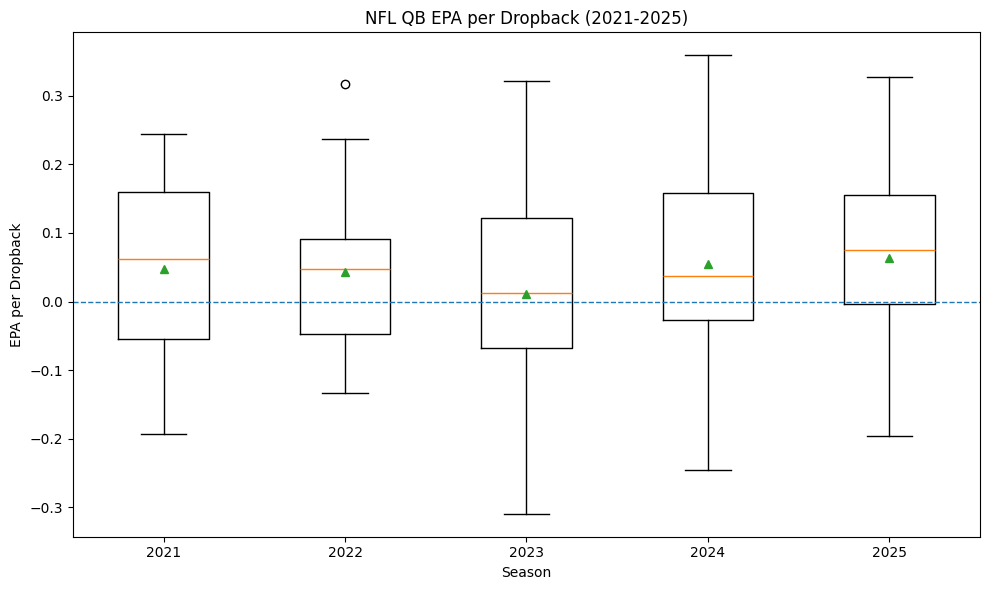

In [ ]:
import matplotlib.pyplot as plt

seasons = sorted(qualified_qb["season"].unique())

epa_data = [
    qualified_qb.loc[
        qualified_qb["season"] == season,
        "epa_per_dropback"
    ]
    for season in seasons
]

plt.figure(figsize=(10,6))

plt.boxplot(
    epa_data,
    tick_labels=seasons,
    showmeans=True
)

plt.axhline(0, linestyle="--", linewidth = 1)

plt.title("NFL QB EPA per Dropback (2021-2025)")
plt.xlabel("Season")
plt.ylabel("EPA per Dropback")

plt.tight_layout()
plt.show()

We can tell many things from this basic chart. The 2023 season has the widest distribution, meaning substantial variation in QB efficiency. The 2025 season has the highest median. 2022 has an outlier (Patrick Mahomes). The green triangles represent the means and the orange line represents the medians, showing that unusually high or low performances can heavily influence the range.

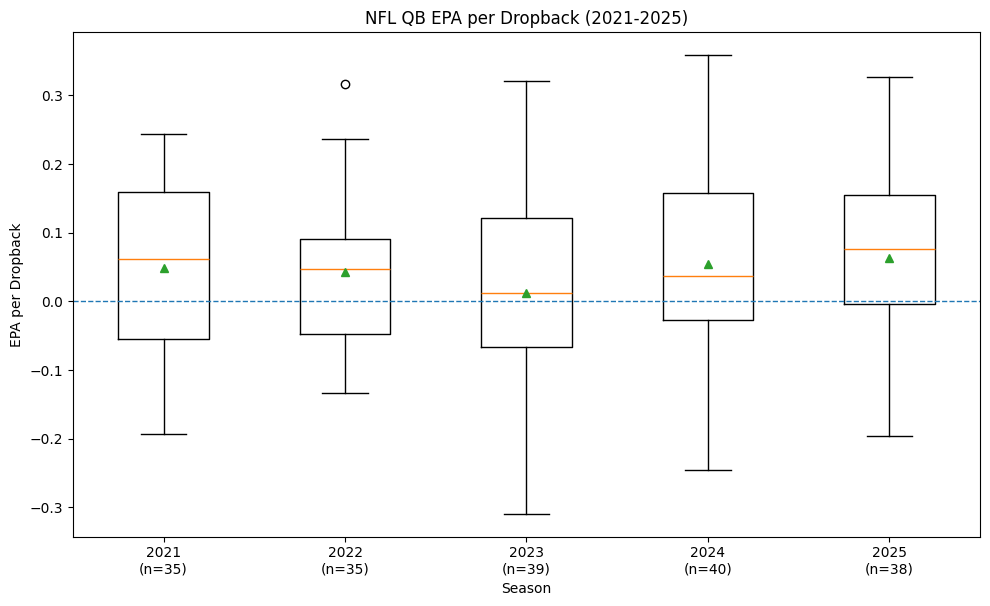

In [ ]:
plt.figure(figsize=(10,6))

plt.boxplot(
    epa_data,
    tick_labels=seasons,
    showmeans=True
)

plt.axhline(0, linestyle="--", linewidth = 1)

plt.title("NFL QB EPA per Dropback (2021-2025)")
plt.xlabel("Season")
plt.ylabel("EPA per Dropback")

plt.tight_layout()

plt.xticks(
    range(1, 6),
    ["2021\n(n=35)",
     "2022\n(n=35)",
     "2023\n(n=39)",
     "2024\n(n=40)",
     "2025\n(n=38)"
     ]
)

plt.show()

Adding qb counts to the different year ticks on the x axis.

In [ ]:
herbert = (
    qualified_qb.loc[
        qualified_qb["qb_name"] == "J.Herbert"
    ]
    .sort_values("season")
    .copy()
)

herbert["season_rank"] = (
    qualified_qb.groupby("season")["epa_per_dropback"]
    .rank(method="min", ascending=False)
    .loc[herbert.index]
)

print(herbert.to_string(index=False))

 season      qb_id   qb_name  dropbacks  total_qb_epa  epa_per_dropback  season_rank
   2021 00-0036355 J.Herbert        745    142.740089          0.191597          5.0
   2022 00-0036355 J.Herbert        758     36.554764          0.048225         17.0
   2023 00-0036355 J.Herbert        517     43.456590          0.084055         15.0
   2024 00-0036355 J.Herbert        576     84.903431          0.147402         13.0
   2025 00-0036355 J.Herbert        615     45.087934          0.073314         20.0


Singling out an individual quarterback (Justin Herbert) to identify trends among epa per dropback per season and to view other factors that affect that metric.

In [ ]:
league_baseline = (
    qualified_qb.groupby("season")["epa_per_dropback"]
    .agg(league_median="median")
)

top_quartile = (
    qualified_qb.groupby("season")["epa_per_dropback"]
    .quantile(0.75)
    .rename("top_quartile")
)

league_baseline = league_baseline.join(top_quartile)

herbert_comparison = (
    herbert[["season", "season_rank", "epa_per_dropback"]]
    .merge(league_baseline, on="season")
)

print(herbert_comparison.round(3).to_string(index=False))

 season  season_rank  epa_per_dropback  league_median  top_quartile
   2021          5.0             0.192          0.061         0.159
   2022         17.0             0.048          0.047         0.091
   2023         15.0             0.084          0.013         0.122
   2024         13.0             0.147          0.037         0.158
   2025         20.0             0.073          0.076         0.155


Comparing Herbert to the league averages and the 75 quartile every season.

In [ ]:
herbert_comparison["above_median"] = (
    herbert_comparison["epa_per_dropback"]
    - herbert_comparison["league_median"]
)

herbert_comparison["gap_to_top_quartile"] = (
    herbert_comparison["epa_per_dropback"]
    - herbert_comparison["top_quartile"]
)

print(herbert_comparison.round(3).to_string(index=False))

 season  season_rank  epa_per_dropback  league_median  top_quartile  above_median  gap_to_top_quartile
   2021          5.0             0.192          0.061         0.159         0.130                0.032
   2022         17.0             0.048          0.047         0.091         0.001               -0.042
   2023         15.0             0.084          0.013         0.122         0.072               -0.038
   2024         13.0             0.147          0.037         0.158         0.110               -0.010
   2025         20.0             0.073          0.076         0.155        -0.002               -0.082


More comparisons showing how far off exactly he was from the league median and 75 quartile.

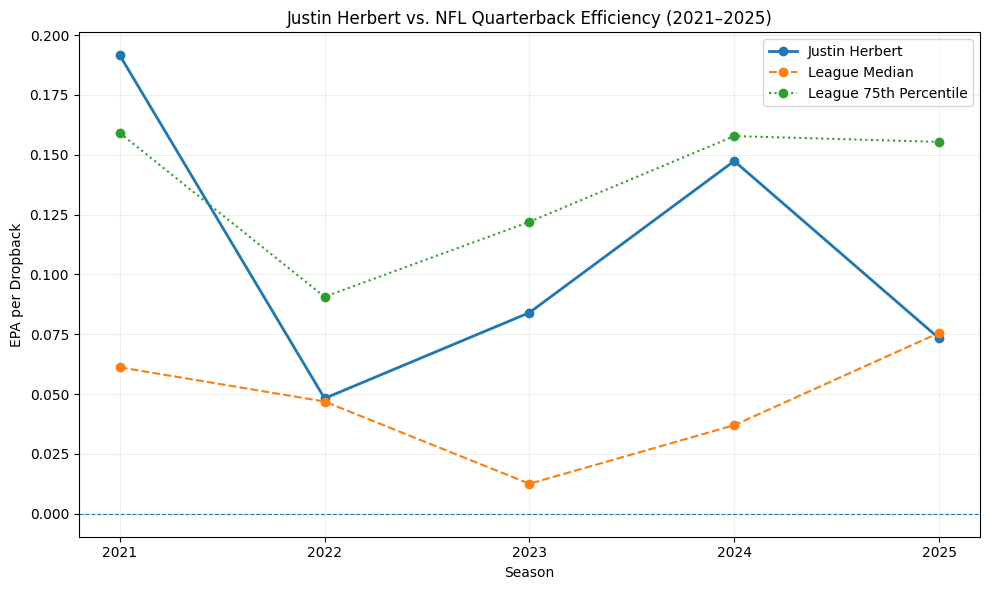

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    herbert_comparison["season"],
    herbert_comparison["epa_per_dropback"],
    marker="o",
    linewidth=2,
    label="Justin Herbert"
)

plt.plot(
    herbert_comparison["season"],
    herbert_comparison["league_median"],
    marker="o",
    linestyle="--",
    label="League Median"
)

plt.plot(
    herbert_comparison["season"],
    herbert_comparison["top_quartile"],
    marker="o",
    linestyle=":",
    label="League 75th Percentile"
)

plt.axhline(0, linestyle="--", linewidth=0.8)

plt.title("Justin Herbert vs. NFL Quarterback Efficiency (2021–2025)")
plt.xlabel("Season")
plt.ylabel("EPA per Dropback")
plt.xticks(herbert_comparison["season"])

plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

Now in graph form: We can officially see that his 2021 season was elite, outperforming more than 75% of the league by a significant margin. This is widely considered his best season, so seeing the other factors will be interesting. 2023 deserves more credit than rankings suggest, because even though he only ranked 15th, his epa exceeded the league median by 0.072. And then we can swee the rebound at the start of the Harbaugh era in 2024, where he ranked near that top 75 mark again.

In [ ]:
factors = [
    "down",
    "ydstogo",
    "yardline_100",
    "score_differential",
    "qtr",
    "game_seconds_remaining",
    "shotgun",
    "no_huddle",
    "play_action",
    "air_yards",
    "pass_location",
    "qb_hit",
    "sack",
    "interception",
    "complete_pass",
    "qb_scramble"
]

factor_check = pd.DataFrame({
    "variable": factors,
    "available": [
        col in dropbacks.columns for col in factors
    ]
})

factor_check["missing_pct"] = [
    dropbacks[col].isna().mean() * 100
    if col in dropbacks.columns else None
    for col in factors
]

factor_check

,variable,available,missing_pct
0,down,True,0.460073
1,ydstogo,True,0.000000
2,yardline_100,True,0.000000
3,score_differential,True,0.000000
4,qtr,True,0.000000
5,game_seconds_remaining,True,0.000000
6,shotgun,True,0.000000
7,no_huddle,True,0.000000
8,play_action,False,NaN
9,air_yards,True,11.812574


This code helps us see which variables exist in the dataset and see what percentage of observations are missing for each variable.

In [ ]:
missing_down = dropbacks.assign(
    down_missing=dropbacks["down"].isna()
)

missing_down_summary = (
    missing_down
    .groupby("down_missing")
    .agg(
        dropbacks=("qb_epa", "size"),
        avg_epa=("qb_epa", "mean"),
        scramble_rate=("qb_scramble", "mean"),
        sack_rate=("sack", "mean"),
        pass_rate=("play_type", lambda x: (x == "pass").mean())
    )
)

missing_down_summary

,dropbacks,avg_epa,scramble_rate,sack_rate,pass_rate
down_missing,,,,,
False,106664,0.047409,0.049567,0.064445,0.950433
True,493,-0.070732,0.000000,0.000000,1.000000


This compares dropbacks with and without the recorded down. If the missing values are concentrated within one kind of play then removing them would introduce bias into the final analysis.

In [ ]:
dropbacks.loc[
    dropbacks["down"].isna(),
    "play_type"
].value_counts(dropna=False)

,count
play_type,
pass,493


This finds the exact amount of pass plays where the down is not available.

In [ ]:
down_analysis = (
    dropbacks.loc[dropbacks["down"].notna()]
    .groupby("down")
    .agg(
        dropbacks=("qb_epa", "size"),
        total_epa=("qb_epa", "sum"),
        avg_epa=("qb_epa", "mean"),
        median_epa=("qb_epa", "median"),
        success_rate=("success", "mean")
    )
    .reset_index()
)

down_analysis

,down,dropbacks,total_epa,avg_epa,median_epa,success_rate
0,1.0,38752,3528.904986,0.091064,-0.048411,0.481756
1,2.0,36160,3007.697665,0.083177,-0.090588,0.470437
2,3.0,28999,-1356.610231,-0.046781,-0.642910,0.396669
3,4.0,2753,-123.205047,-0.044753,-1.188462,0.462041


This creates a summary using observations with a recorded down only. We can see a relationship between down and quarterback efficiency, in particular that the average epa on first and second down is much higher than on third and fouth down. Fourth down probably needs more context because of the limited dropbacks in the sample. It is very interesting that the median epa is negative on every down though, which shows that a smaller amount of high value plays can pull the average upward.

In [ ]:
dropbacks["distance_category"] = pd.cut(
    dropbacks["ydstogo"],
    bins=[-float("inf"), 3, 6, 10, float("inf")],
    labels=["Short (1-3)", "Medium (4-6)", "Long (7-10)", "Very Long (11+)"]
)

down_distance_analysis = (
    dropbacks.loc[dropbacks["down"].notna()]
    .groupby(
        ["down", "distance_category"],
        observed=True
    )
    .agg(
        dropbacks=("qb_epa", "size"),
        avg_epa=("qb_epa", "mean"),
        success_rate=("success", "mean")
    )
    .reset_index()
)

down_distance_analysis

,down,distance_category,dropbacks,avg_epa,success_rate
0,1.0,Short (1-3),470,0.027921,0.461702
1,1.0,Medium (4-6),669,0.011092,0.460389
2,1.0,Long (7-10),35546,0.096104,0.484780
3,1.0,Very Long (11+),2067,0.044623,0.441219
4,2.0,Short (1-3),3502,0.072729,0.553398
5,2.0,Medium (4-6),7383,0.112086,0.515373
6,2.0,Long (7-10),18382,0.097956,0.456479
7,2.0,Very Long (11+),6893,0.018113,0.417380
8,3.0,Short (1-3),5383,-0.021372,0.535203
9,3.0,Medium (4-6),8121,0.027792,0.451792


Now looking at the relationships between down and distnce, by accounting for distance in buckets of short (1-3), medium (4-6), long (7-10), and very long (11+) yardages to go.

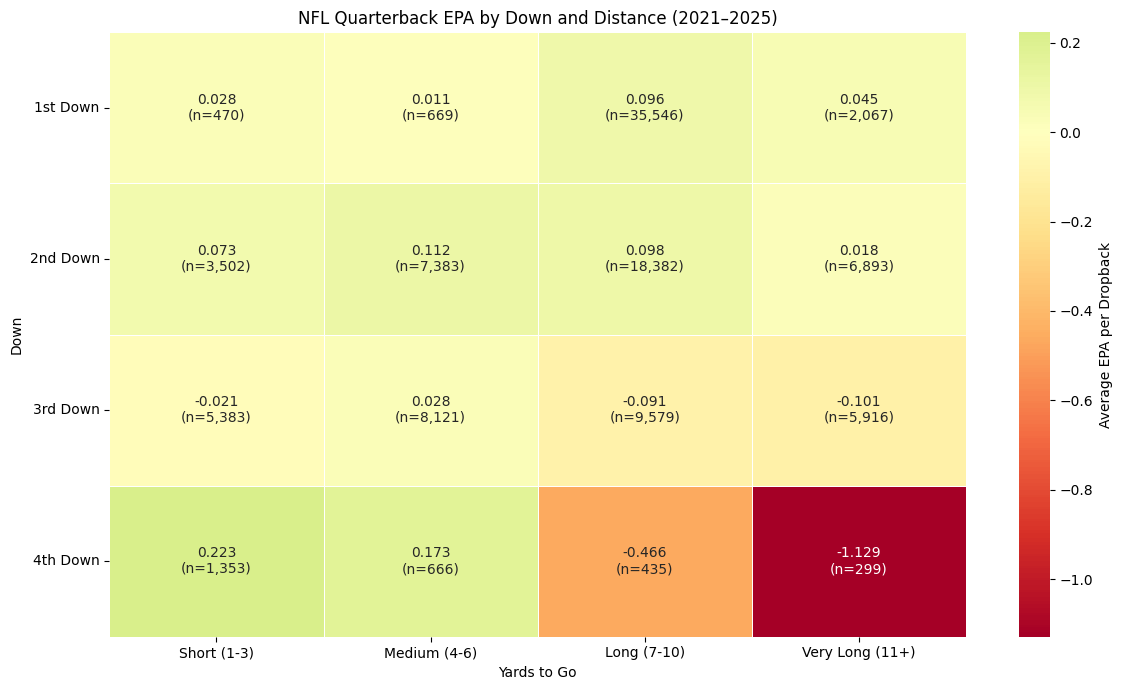

In [ ]:
import seaborn as sns

count_pivot = down_distance_analysis.pivot(
    index="down",
    columns="distance_category",
    values="dropbacks"
)

epa_labels = epa_pivot.copy().astype(object)

for down in epa_pivot.index:
    for distance in epa_pivot.columns:
        epa_value = epa_pivot.loc[down, distance]
        count = count_pivot.loc[down, distance]

        epa_labels.loc[down, distance] = (
            f"{epa_value:.3f}\n(n={count:,.0f})"
        )

plt.figure(figsize=(12, 7))

sns.heatmap(
    epa_pivot,
    annot=epa_labels,
    fmt="",
    cmap="RdYlGn",
    center=0,
    linewidths=0.5,
    cbar_kws={"label": "Average EPA per Dropback"}
)

plt.title("NFL Quarterback EPA by Down and Distance (2021–2025)")
plt.xlabel("Yards to Go")
plt.ylabel("Down")

plt.yticks(
    ticks=[0.5, 1.5, 2.5, 3.5],
    labels=["1st Down", "2nd Down", "3rd Down", "4th Down"],
    rotation=0
)

plt.tight_layout()
plt.show()

Now looking at it with a heat map. We can see on first and second down that the averages stay positive and that averages for third and fourth down stay negative but improve as the yardage to go is less. First and short / medium is likely on the goal line or after a penalty, which is why the number of observations is probably lower.

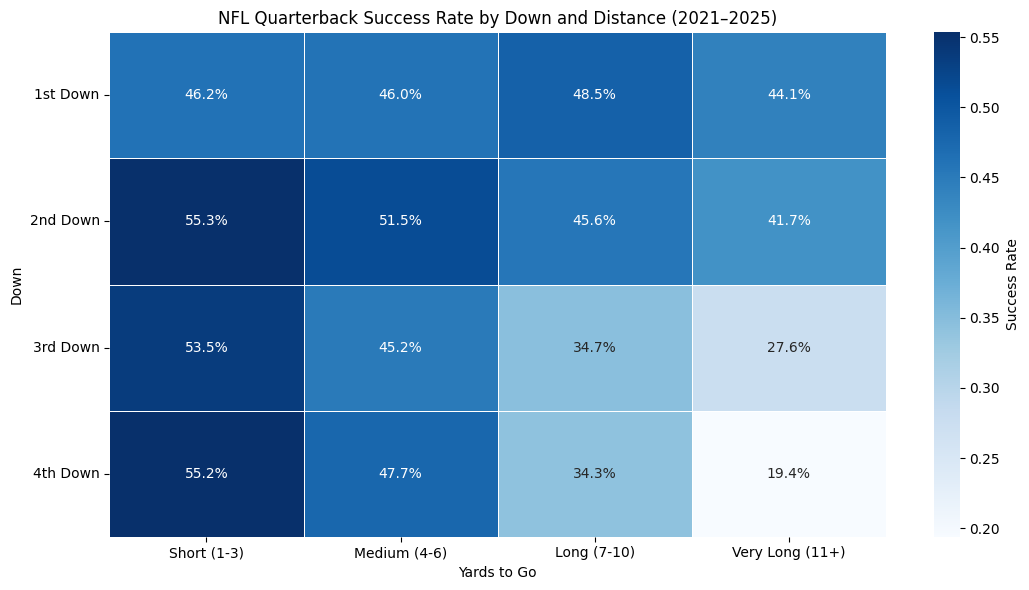

In [ ]:
success_pivot = down_distance_analysis.pivot(
    index="down",
    columns="distance_category",
    values="success_rate"
)

plt.figure(figsize=(11, 6))

sns.heatmap(
    success_pivot,
    annot=True,
    fmt=".1%",
    cmap="Blues",
    linewidths=0.5,
    cbar_kws={"label": "Success Rate"}
)

plt.title("NFL Quarterback Success Rate by Down and Distance (2021–2025)")
plt.xlabel("Yards to Go")
plt.ylabel("Down")

plt.yticks(
    ticks=[0.5, 1.5, 2.5, 3.5],
    labels=["1st Down", "2nd Down", "3rd Down", "4th Down"],
    rotation=0
)

plt.tight_layout()
plt.show()

Using the success rate as a metric, we can compare how the epa in different situations compares to the success on a given play.

In [ ]:
dropbacks["field_position"] = pd.cut(
    dropbacks["yardline_100"],
    bins=[0, 10, 20, 40, 60, 80, 100],
    labels=[
        "Inside 10 (0-10)",
        "Red Zone (11-20)",
        "Opponent Territory (21-40)",
        "Midfield (41-60)",
        "Own Territory (61-80)",
        "Backed Up (81-100)"
    ],
    include_lowest=True
)

field_position_analysis = (
    dropbacks
    .groupby("field_position", observed=True)
    .agg(
        dropbacks=("qb_epa", "size"),
        avg_epa=("qb_epa", "mean"),
        median_epa=("qb_epa", "median"),
        success_rate=("success", "mean")
    )
    .reset_index()
)

field_position_analysis

,field_position,dropbacks,avg_epa,median_epa,success_rate
0,Inside 10 (0-10),6918,0.006558,-0.434668,0.420353
1,Red Zone (11-20),7971,0.052878,-0.360792,0.403713
2,Opponent Territory (21-40),19865,0.059698,-0.124709,0.468613
3,Midfield (41-60),28036,0.045939,-0.169313,0.462512
4,Own Territory (61-80),36061,0.045876,-0.112043,0.459028
5,Backed Up (81-100),8306,0.051391,-0.139905,0.447628


Now looking at field position compared to epa. We can see that quarterbacks are the most efficient when in opponent territory, and that average epa actually drops as the field shortens, with smaller passing windows and the different nature of goal-line situations. Field position alone doesn't explain as much of the variation as we would like and it is important to note that Epa already accounts for the expected-points value of the starting field position.

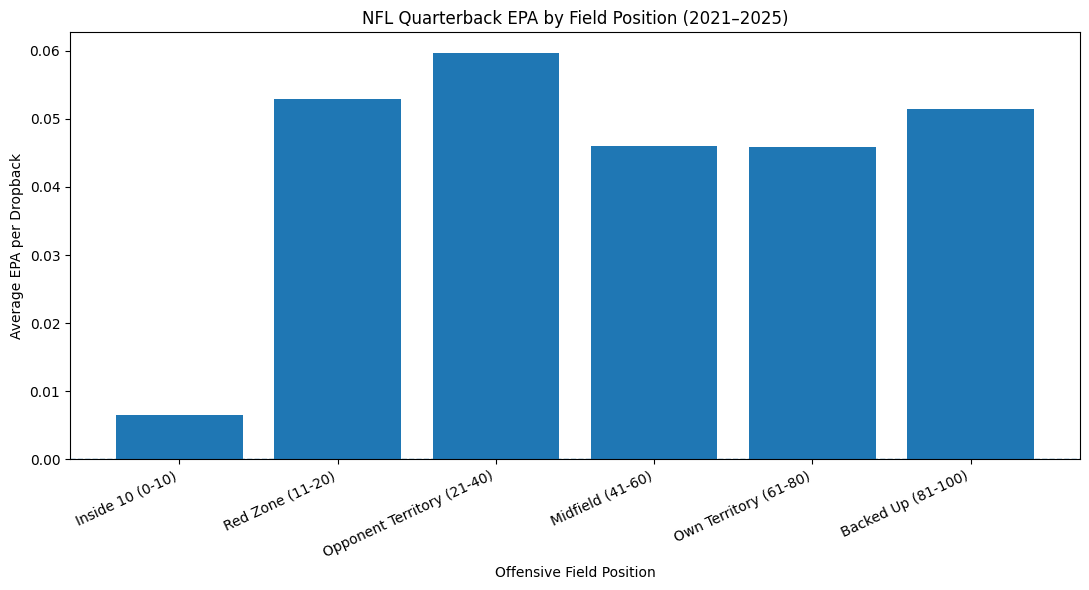

In [ ]:
field_plot = field_position_analysis.copy()

plt.figure(figsize=(11, 6))

plt.bar(
    field_plot["field_position"].astype(str),
    field_plot["avg_epa"]
)

plt.axhline(0, linestyle="--", linewidth=1)

plt.title("NFL Quarterback EPA by Field Position (2021–2025)")
plt.xlabel("Offensive Field Position")
plt.ylabel("Average EPA per Dropback")
plt.xticks(rotation=25, ha="right")

plt.tight_layout()
plt.show()

Same observations, but with a bar plot.

In [ ]:
dropbacks["score_category"] = pd.cut(
    dropbacks["score_differential"],
    bins=[-float("inf"), -7.5, -0.5, 0.5, 7.5, float("inf")],
    labels=[
        "Trailing by 8+",
        "Trailing by 1-7",
        "Tied",
        "Leading by 1-7",
        "Leading by 8+"
    ]
)

score_analysis = (
    dropbacks
    .groupby("score_category", observed=True)
    .agg(
        dropbacks=("qb_epa", "size"),
        total_epa=("qb_epa", "sum"),
        avg_epa=("qb_epa", "mean"),
        median_epa=("qb_epa", "median")
    )
    .reset_index()
)

score_analysis

,score_category,dropbacks,total_epa,avg_epa,median_epa
0,Trailing by 8+,27576,-508.384260,-0.018436,-0.202082
1,Trailing by 1-7,28360,1460.524446,0.051499,-0.152279
2,Tied,20028,936.653753,0.046767,-0.163388
3,Leading by 1-7,19279,1682.940790,0.087294,-0.159502
4,Leading by 8+,11914,1450.181643,0.121721,-0.136820


Now, we look at score differential and epa, which leads to one of our biggest relationships because qb epa tends to be greater when their team is leading by more compared to trailing. However, we know that stronger teams will be more likely to lead, and better quarterback performances may help create that lead in the first place, so we cannot conclude that leading causes better epa.

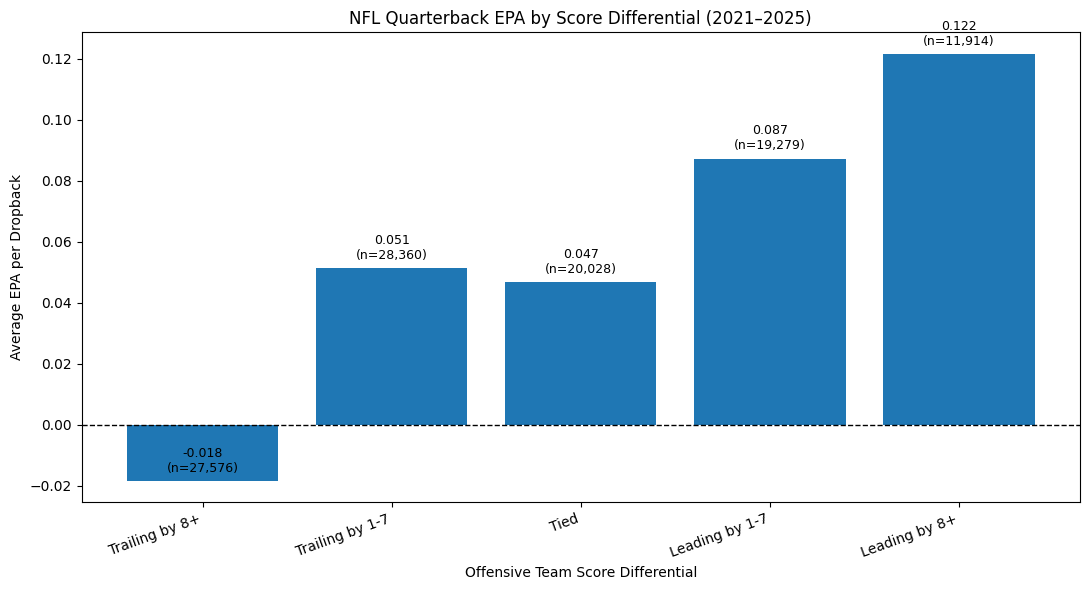

In [ ]:
plt.figure(figsize=(11, 6))

plt.bar(
    score_analysis["score_category"].astype(str),
    score_analysis["avg_epa"]
)

plt.axhline(0, linestyle="--", linewidth=1, color="black")

plt.title("NFL Quarterback EPA by Score Differential (2021–2025)")
plt.xlabel("Offensive Team Score Differential")
plt.ylabel("Average EPA per Dropback")
plt.xticks(rotation=20, ha="right")

for i, row in score_analysis.iterrows():
    plt.text(
        i,
        row["avg_epa"] + 0.003,
        f'{row["avg_epa"]:.3f}\n(n={row["dropbacks"]:,})',
        ha="center",
        fontsize=9
    )

plt.tight_layout()
plt.show()

Same thing, but in a bar plot.

In [ ]:
quarter_analysis = (
    dropbacks
    .groupby("qtr")
    .agg(
        dropbacks=("qb_epa", "size"),
        avg_epa=("qb_epa", "mean"),
        median_epa=("qb_epa", "median"),
        total_epa=("qb_epa", "sum")
    )
    .reset_index()
)

quarter_analysis

,qtr,dropbacks,avg_epa,median_epa,total_epa
0,1.0,22716,0.039481,-0.174077,896.842136
1,2.0,30565,0.087725,-0.120512,2681.301310
2,3.0,23223,0.038794,-0.214955,900.911102
3,4.0,29914,0.015107,-0.202475,451.903067
4,5.0,739,0.123084,-0.084293,90.958758


Now looking at quarters, we can see that the second quarter produces the highest average epa during regualtion, and overtime produces the highest overall. Fourth quarter efficiency is relatively low, which may be connected to the trailing factor from the last calculation and how teams may run the ball more frequently if they are in the lead to drain the clock out.

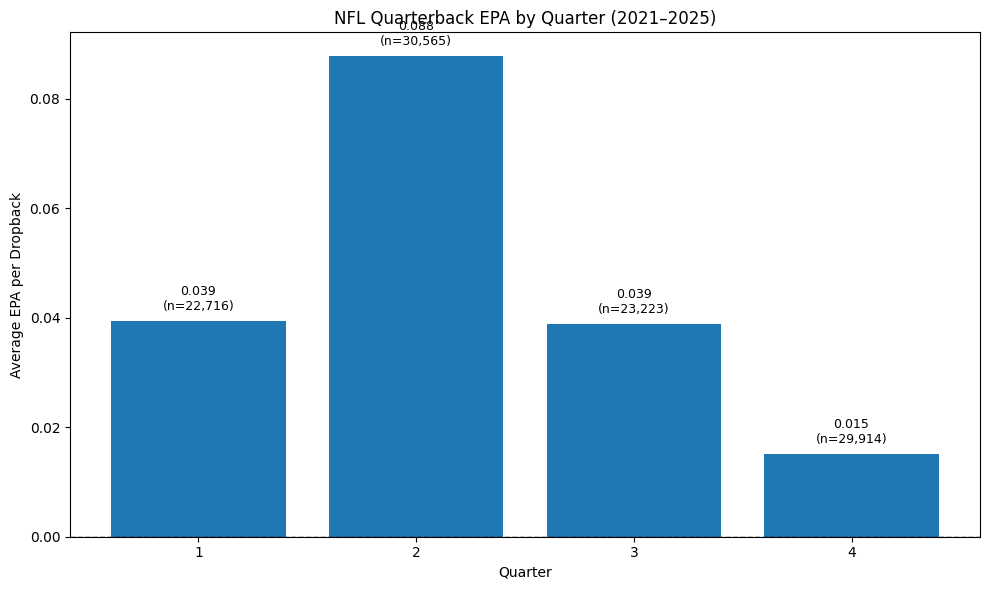

In [ ]:
regulation_quarters = quarter_analysis.loc[
    quarter_analysis["qtr"] <= 4
].copy()

plt.figure(figsize=(10, 6))

plt.bar(
    regulation_quarters["qtr"].astype(int).astype(str),
    regulation_quarters["avg_epa"]
)

plt.axhline(0, linestyle="--", linewidth=1, color="black")

plt.title("NFL Quarterback EPA by Quarter (2021–2025)")
plt.xlabel("Quarter")
plt.ylabel("Average EPA per Dropback")

for i, row in enumerate(regulation_quarters.itertuples()):
    plt.text(
        i,
        row.avg_epa + 0.002,
        f"{row.avg_epa:.3f}\n(n={row.dropbacks:,})",
        ha="center",
        fontsize=9
    )

plt.tight_layout()
plt.show()

Same calculations, but in a bar plot. Leaving out overtime so it doesn't distort the scale of values.

In [ ]:
dropbacks["time_category"] = pd.cut(
    dropbacks["game_seconds_remaining"],
    bins=[0, 300, 600, 900, float("inf")],
    labels=[
        "0-5 Minutes",
        "5-10 Minutes",
        "10-15 Minutes",
        "15+ Minutes"
    ],
    include_lowest=True
)

time_analysis = (
    dropbacks
    .groupby("time_category", observed=True)
    .agg(
        dropbacks=("qb_epa", "size"),
        avg_epa=("qb_epa", "mean"),
        median_epa=("qb_epa", "median")
    )
    .reset_index()
)

time_analysis

,time_category,dropbacks,avg_epa,median_epa
0,0-5 Minutes,12754,0.019759,-0.163696
1,5-10 Minutes,9018,-0.001431,-0.277691
2,10-15 Minutes,8884,0.033933,-0.231163
3,15+ Minutes,76501,0.058579,-0.152302


This shows us how epa changes within the last 5 minutes, 10 minutes, 15 minutes, and beyond of the end of the game. Most of the observations occur at 15+ minutes because this code accounts for the seconds remaining in the game, so everything starts from its distance from the end. But, we can make our observations from the different marks of the fourth quarter or overtime. The final 5 minutes have relatively low epa, but within the last 5-10 minutes has the lowest compared to the rest of the game.

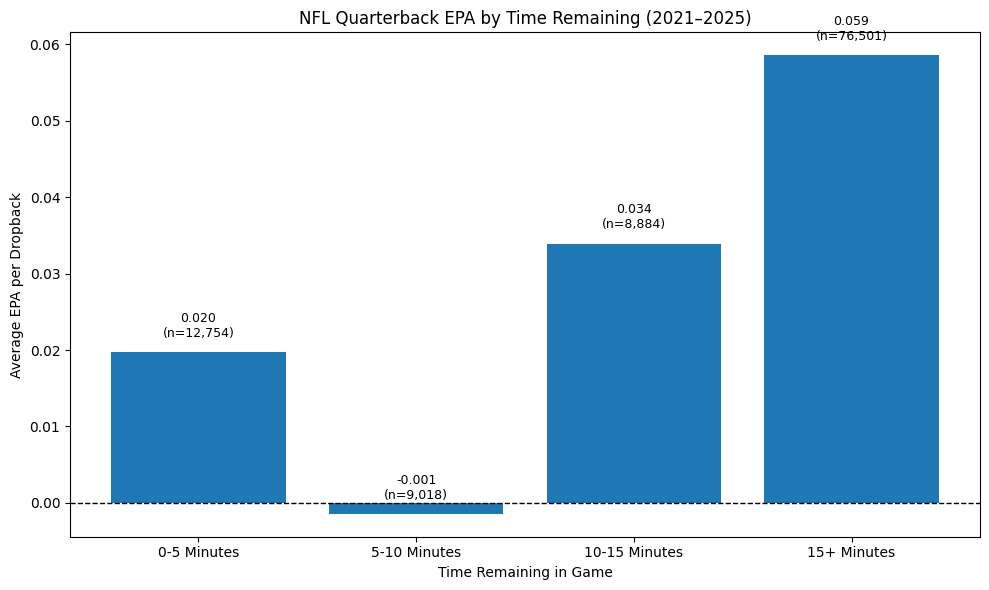

In [ ]:
plt.figure(figsize=(10, 6))

plt.bar(
    time_analysis["time_category"].astype(str),
    time_analysis["avg_epa"]
)

plt.axhline(0, linestyle="--", linewidth=1, color="black")

plt.title("NFL Quarterback EPA by Time Remaining (2021–2025)")
plt.xlabel("Time Remaining in Game")
plt.ylabel("Average EPA per Dropback")

for i, row in time_analysis.iterrows():
    plt.text(
        i,
        row["avg_epa"] + 0.002,
        f'{row["avg_epa"]:.3f}\n(n={row["dropbacks"]:,})',
        ha="center",
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [ ]:
dropbacks["shotgun"].value_counts(dropna=False)

shotgun_analysis = (
    dropbacks
    .groupby("shotgun")
    .agg(
        dropbacks=("qb_epa", "size"),
        total_epa=("qb_epa", "sum"),
        avg_epa=("qb_epa", "mean"),
        median_epa=("qb_epa", "median"),
        success_rate=("success", "mean")
    )
    .reset_index()
)

shotgun_analysis["formation"] = shotgun_analysis["shotgun"].map({
    0: "Under Center",
    1: "Shotgun"
})

shotgun_analysis

,shotgun,dropbacks,total_epa,avg_epa,median_epa,success_rate,formation
0,0.0,17703,2363.920079,0.133532,-0.005471,0.497034,Under Center
1,1.0,89454,2657.996294,0.029714,-0.184919,0.445749,Shotgun


Now that we have investigated the main game factors, we can go into play characteristics, such as shotgun vs under center comparisons seen here. Under center dropbacks have a considerably higher average epa despite the significantly lower amount of dropbacks.

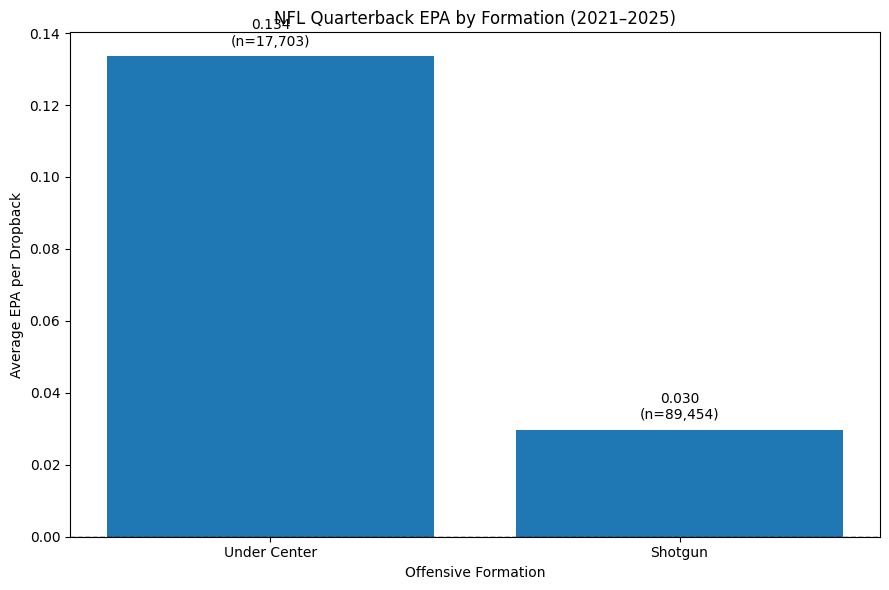

In [ ]:
formation_plot = shotgun_analysis.sort_values(
    "shotgun"
)

plt.figure(figsize=(9, 6))

plt.bar(
    formation_plot["formation"],
    formation_plot["avg_epa"]
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1,
    color="black"
)

plt.title("NFL Quarterback EPA by Formation (2021–2025)")
plt.xlabel("Offensive Formation")
plt.ylabel("Average EPA per Dropback")

for i, row in formation_plot.reset_index(drop=True).iterrows():
    plt.text(
        i,
        row["avg_epa"] + 0.003,
        f'{row["avg_epa"]:.3f}\n(n={row["dropbacks"]:,})',
        ha="center",
        fontsize=10
    )

plt.tight_layout()
plt.show()

Here is that bar chart for shotgun vs under-center.

In [ ]:
tempo_analysis = (
    dropbacks
    .groupby("no_huddle")
    .agg(
        dropbacks=("qb_epa", "size"),
        total_epa=("qb_epa", "sum"),
        avg_epa=("qb_epa", "mean"),
        median_epa=("qb_epa", "median"),
        success_rate=("success", "mean")
    )
    .reset_index()
)

tempo_analysis["offensive_tempo"] = (
    tempo_analysis["no_huddle"]
    .map({
        0: "Standard",
        1: "No Huddle"
    })
)

tempo_analysis

,no_huddle,dropbacks,total_epa,avg_epa,median_epa,success_rate,offensive_tempo
0,0.0,94214,4175.630167,0.044321,-0.183666,0.449912,Standard
1,1.0,12943,846.286205,0.065386,-0.046776,0.485591,No Huddle


Here is the comparison of epa in situations with no huddle vs standard play procedures. No huddle dropbacks tend to have a higher average and median epa compared to standard tempo dropbacks. Again, it is a much smaller sample compared to the average game situation, but some differences can at least be observed.

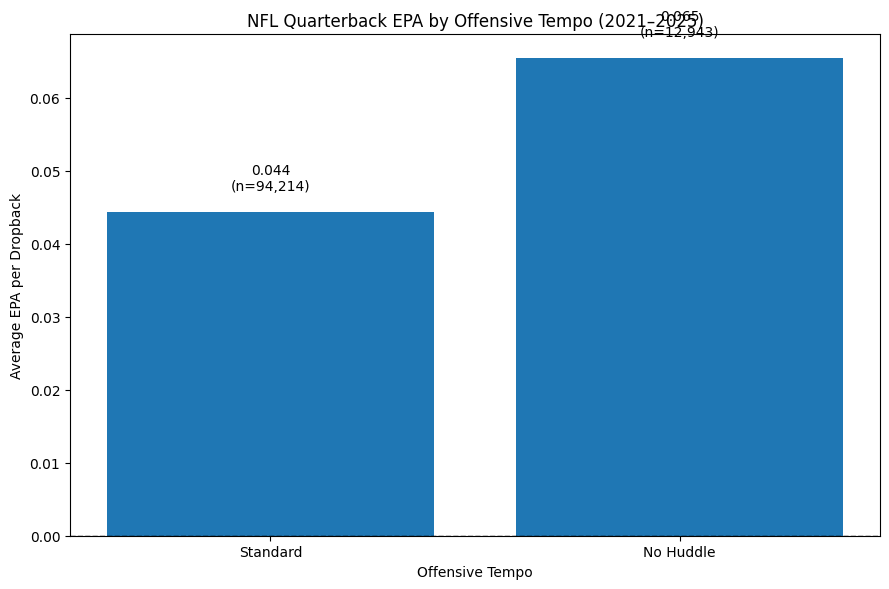

In [ ]:
tempo_plot = tempo_analysis.sort_values("no_huddle")

plt.figure(figsize=(9, 6))

plt.bar(
    tempo_plot["offensive_tempo"],
    tempo_plot["avg_epa"]
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1,
    color="black"
)

plt.title("NFL Quarterback EPA by Offensive Tempo (2021–2025)")
plt.xlabel("Offensive Tempo")
plt.ylabel("Average EPA per Dropback")

for i, row in tempo_plot.reset_index(drop=True).iterrows():
    plt.text(
        i,
        row["avg_epa"] + 0.003,
        f'{row["avg_epa"]:.3f}\n(n={row["dropbacks"]:,})',
        ha="center",
        fontsize=10
    )

plt.tight_layout()
plt.show()

Now in bar plots

In [ ]:
dropbacks["air_yards"].describe()

,air_yards
count,94499.000000
mean,7.773733
std,10.165346
min,-20.000000
25%,1.000000
50%,5.000000
75%,12.000000
max,65.000000


In [ ]:
dropbacks["air_yards"].isna().value_counts()

,count
air_yards,
False,94499
True,12658


In [ ]:
analysis_dropbacks = dropbacks.loc[
    dropbacks["season_type"] == "REG"
].copy()

analysis_dropbacks["season_type"].value_counts()
analysis_dropbacks.shape

(102020, 378)

In [ ]:
analysis_dropbacks.loc[
    analysis_dropbacks["air_yards"].isna(),
    ["play_type", "qb_scramble", "sack", "complete_pass"]
].value_counts(dropna=False).head(15)

play_type  qb_scramble  sack  complete_pass
pass       0.0          1.0   0.0              6552
run        1.0          0.0   0.0              5001
pass       0.0          0.0   0.0               471
                              1.0                 1
Name: count, dtype: int64

In [ ]:
analysis_dropbacks["air_yards"].isna().sum()

analysis_dropbacks.loc[
    analysis_dropbacks["air_yards"].isna(),
    ["play_type", "qb_scramble", "sack", "complete_pass"]
].value_counts(dropna=False)

play_type  qb_scramble  sack  complete_pass
pass       0.0          1.0   0.0              6552
run        1.0          0.0   0.0              5001
pass       0.0          0.0   0.0               471
                              1.0                 1
Name: count, dtype: int64